Praktikum 1 - Pra pengolahan data & ekstraksi fitur data terstruktur (Titanic).

Imputasi missing value lalu ekstraksi fitur turunan:
FamilySize, Title, AgeBin, CabinDeck, FarePerPerson.
Output: output/*.png, data/Titanic-Dataset-fixed.csv

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("ekstraksi_fitur_terstruktur.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js03-ektraksi-fitur\praktikum-1


In [2]:
from pathlib import Path

import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
import seaborn as sns

HERE = Path(__file__).resolve().parent
DATA = HERE.parent / "data"
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

In [3]:
# Langkah 1 - load data
df = pd.read_csv(DATA / "Titanic-Dataset.csv")
print("=== df.head() ===")
print(df.head())

=== df.head() ===
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500  

In [4]:
# Langkah 2 - pengecekan data
print("\n=== df.info() ===")
df.info()
print("\n=== Missing value per kolom ===")
print(df.isnull().sum())


=== df.info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

=== Missing value per kolom ===
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Ca

In [5]:
# Langkah 3 - imputasi
# Catatan: modul menulis df['Embarked'].mode (tanpa kurung) yang menyisipkan
# Series, bukan nilai modus. Di sini dipakai mode()[0] agar benar.
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Cabin"] = df["Cabin"].fillna("DECK")
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [6]:
# Langkah 4 - validasi hasil imputasi
print("\n=== Setelah imputasi: jumlah missing ===")
print(df.isnull().sum())
print(f"Age rata-rata dipakai untuk imputasi : {df['Age'].mean():.4f}")
print(f"Embarked modus dipakai untuk imputasi: {df['Embarked'].mode()[0]}")


=== Setelah imputasi: jumlah missing ===
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64
Age rata-rata dipakai untuk imputasi : 29.6991
Embarked modus dipakai untuk imputasi: S


In [7]:
# Langkah 5 - ekstraksi fitur
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False)
# nama seperti "Rothes, the Countess. of..." menghasilkan "the Countess";
# prefix "the " dibuang agar ikut terpetakan ke "Rare".
df["Title"] = df["Title"].str.replace(r"^the\s+", "", regex=True)
df["Title"] = df["Title"].replace({
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Lady": "Rare", "Countess": "Rare", "Capt": "Rare", "Col": "Rare",
    "Don": "Rare", "Dr": "Rare", "Major": "Rare", "Rev": "Rare",
    "Sir": "Rare", "Jonkheer": "Rare", "Dona": "Rare",
})
df["AgeBin"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
                      labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"])
df["CabinDeck"] = df["Cabin"].astype(str).str[0]
df["FarePerPerson"] = df["Fare"] / df["FamilySize"]

print("\n=== Hasil ekstraksi fitur (5 baris) ===")
print(df[["Name", "Title", "Age", "AgeBin", "FamilySize", "Cabin", "CabinDeck",
          "FarePerPerson"]].head().to_string())

print("\n=== Distribusi fitur baru ===")
for col in ["Title", "AgeBin", "CabinDeck"]:
    print(f"{col}: {df[col].value_counts().to_dict()}")
print(f"FamilySize min/max/mean: {df['FamilySize'].min()}/"
      f"{df['FamilySize'].max()}/{df['FamilySize'].mean():.3f}")
print(f"FarePerPerson min/max: {df['FarePerPerson'].min():.4f}/"
      f"{df['FarePerPerson'].max():.4f}")


=== Hasil ekstraksi fitur (5 baris) ===
                                                  Name Title   Age      AgeBin  FamilySize Cabin CabinDeck  FarePerPerson
0                              Braund, Mr. Owen Harris    Mr  22.0  YoungAdult           2  DECK         D        3.62500
1  Cumings, Mrs. John Bradley (Florence Briggs Thayer)   Mrs  38.0       Adult           2   C85         C       35.64165
2                               Heikkinen, Miss. Laina  Miss  26.0  YoungAdult           1  DECK         D        7.92500
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)   Mrs  35.0  YoungAdult           2  C123         C       26.55000
4                             Allen, Mr. William Henry    Mr  35.0  YoungAdult           1  DECK         D        8.05000

=== Distribusi fitur baru ===
Title: {'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}
AgeBin: {'YoungAdult': 535, 'Adult': 195, 'Teen': 70, 'Child': 69, 'Senior': 22}
CabinDeck: {'D': 720, 'C': 59, 'B': 47, 'E': 

In [8]:
# survival rate per fitur baru
print("\n=== Survival rate per Title ===")
print(df.groupby("Title")["Survived"].agg(["mean", "count"]).sort_values("mean"))
print("\n=== Survival rate per AgeBin ===")
print(df.groupby("AgeBin", observed=True)["Survived"].agg(["mean", "count"]))
print("\n=== Survival rate per CabinDeck ===")
print(df.groupby("CabinDeck")["Survived"].agg(["mean", "count"]).sort_values("mean"))

df.to_csv(DATA / "Titanic-Dataset-fixed.csv", index=False)
print(f"\nDataset hasil imputasi disimpan: {DATA / 'Titanic-Dataset-fixed.csv'}")


=== Survival rate per Title ===
            mean  count
Title                  
Mr      0.156673    517
Rare    0.347826     23
Master  0.575000     40
Miss    0.702703    185
Mrs     0.793651    126

=== Survival rate per AgeBin ===
                mean  count
AgeBin                     
Child       0.579710     69
Teen        0.428571     70
YoungAdult  0.353271    535
Adult       0.400000    195
Senior      0.227273     22

=== Survival rate per CabinDeck ===
               mean  count
CabinDeck                 
T          0.000000      1
D          0.320833    720
A          0.466667     15
G          0.500000      4
C          0.593220     59
F          0.615385     13
B          0.744681     47
E          0.750000     32

Dataset hasil imputasi disimpan: C:\code\pemmes26\js03-ektraksi-fitur\data\Titanic-Dataset-fixed.csv


grafik -> output/p1_familysize.png


grafik -> output/p1_title.png


grafik -> output/p1_agebin.png


grafik -> output/p1_cabindeck.png

Selesai praktikum 1.


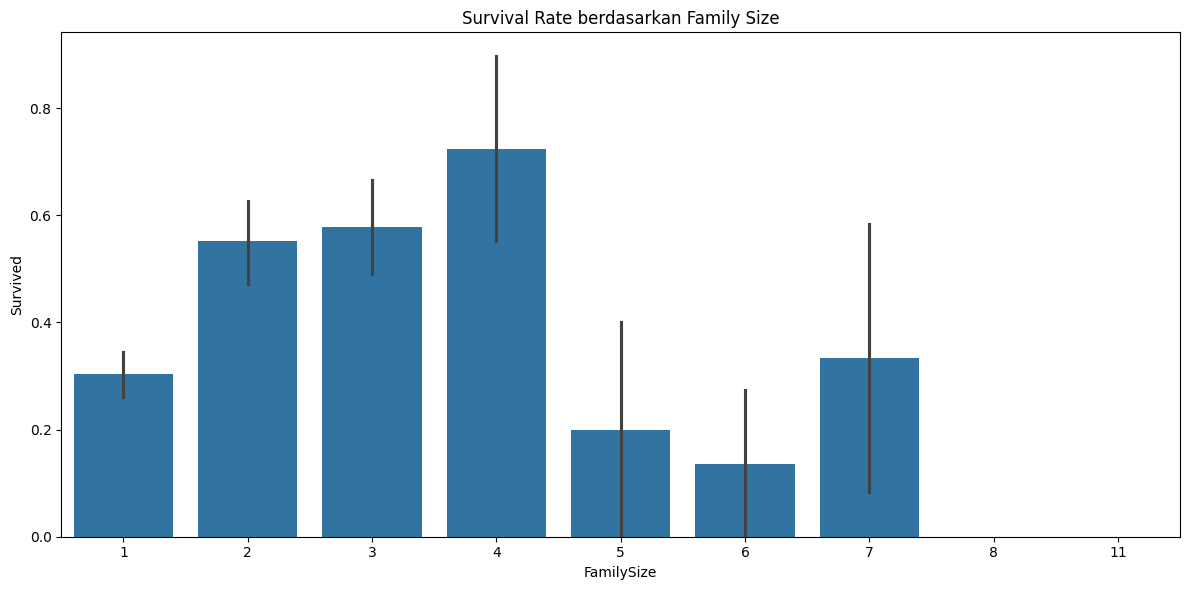

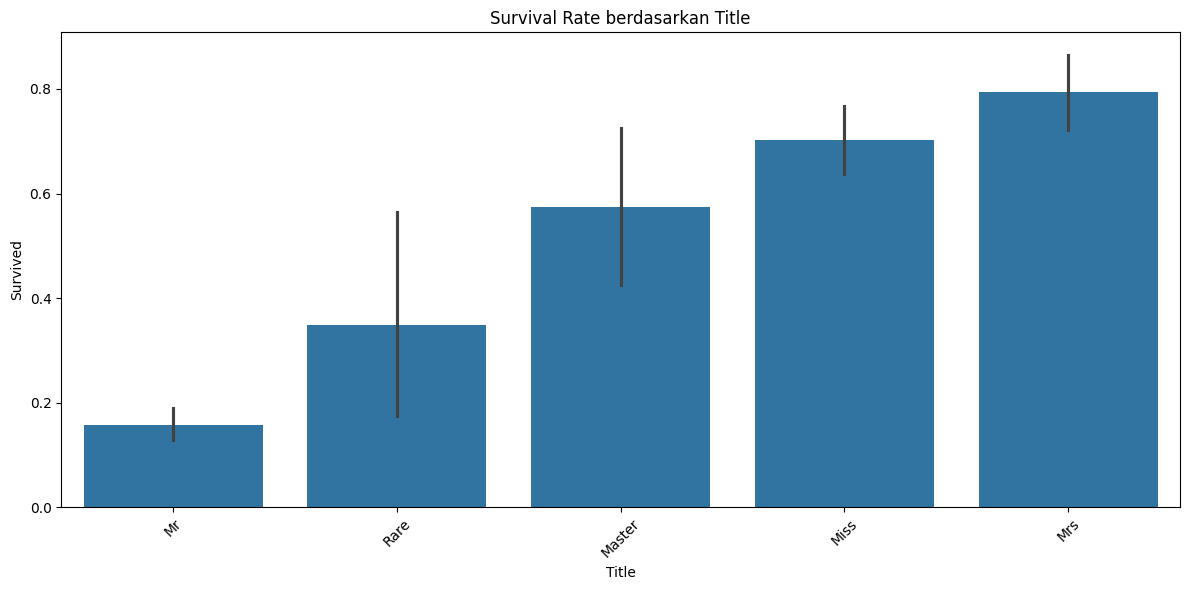

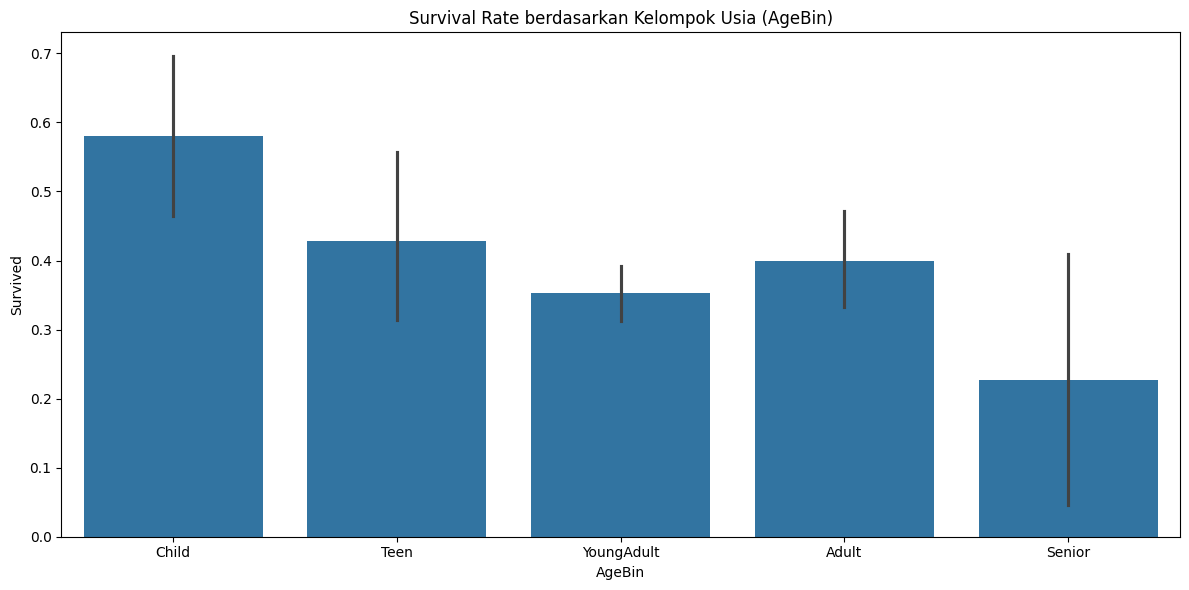

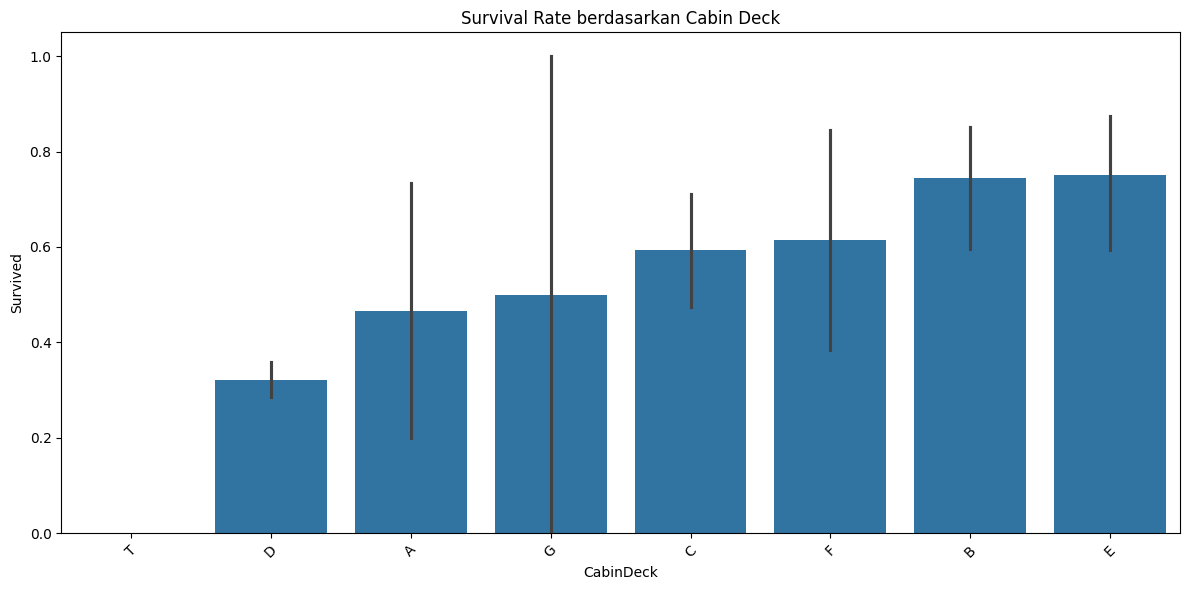

In [9]:
# Langkah 6 - visualisasi
plots = [
    ("FamilySize", "Survival Rate berdasarkan Family Size", "p1_familysize.png", None),
    ("Title", "Survival Rate berdasarkan Title", "p1_title.png",
     df.groupby("Title")["Survived"].mean().sort_values().index),
    ("AgeBin", "Survival Rate berdasarkan Kelompok Usia (AgeBin)", "p1_agebin.png",
     ["Child", "Teen", "YoungAdult", "Adult", "Senior"]),
    ("CabinDeck", "Survival Rate berdasarkan Cabin Deck", "p1_cabindeck.png",
     df.groupby("CabinDeck")["Survived"].mean().sort_values().index),
]
for x, title, fname, order in plots:
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.barplot(x=x, y="Survived", data=df, order=order, ax=ax)
    ax.set_title(title)
    if x in ("Title", "CabinDeck"):
        ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=120)
    print(f"grafik -> output/{fname}")

print("\nSelesai praktikum 1.")